# La idea de la tarjeta de puntaje: peso de la evidencia, valor de información y puntos

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el tema 01 (primeros pasos)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué miden el peso de la evidencia (WoE) y el valor de información (IV) de una variable agrupada en tramos, y recalcular ambos desde los conteos de un tramo;
- explicar cómo un modelo logístico sobre WoE se convierte en una tabla de puntos, y qué significa "puntos para duplicar las probabilidades relativas" (PDO);
- recalcular el puntaje de una tarjeta solo con sus puntos, sin el modelo, y mostrar lo que cuesta el redondeo de los puntos;
- leer la discriminación y la tabla de grados de la tarjeta de puntaje sobre las 9.000 tarjetas reservadas.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C01 (PD de tarjetas de crédito minoristas) tal como Contraste los versiona. Las 30.000 tarjetas vienen del archivo de tarjetas de crédito de Taiwán de UCI (Yeh, 2009; CC BY 4.0, clase de licencia `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). El pipeline las dividió una sola vez, con una semilla fija: 16.800 tarjetas para ajustar la tarjeta de puntaje, 4.200 para calibrar a los retadores y una muestra reservada bloqueada de 9.000 tarjetas que ningún ajuste ha visto. Dos archivos versionados contienen todo lo que este cuaderno necesita, así que no ajusta nada y no requiere datos crudos:

- `data/derived/C01/models-taiwan.json`: la tarjeta de puntaje ajustada (escalón P1): sus coeficientes, sus valores de información y su tabla de puntos con los conteos de cada tramo sobre las 16.800 tarjetas de entrenamiento. Dueño: este repositorio.
- `data/derived/C01/holdout.json`: la tarjeta de puntaje sobre la muestra reservada: una muestra de 50 tarjetas con sus entradas crudas, sus puntos, su puntaje y su PD, los 12 grados de la escala maestra y las filas de prueba versionadas.

La siguiente celda carga ambos archivos e imprime lo que contiene la tarjeta de puntaje.

In [2]:
# Cargar los dos archivos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
models = json.loads((derived / "models-taiwan.json").read_text(encoding="utf-8"))
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))

# La tarjeta de puntaje es el modelo con id P1-scorecard
card = next(m for m in models["model"] if m["id"] == "P1-scorecard")["details"]
table = card["points_table"]
print("ajustada sobre", models["fit"]["train_rows"], "tarjetas de entrenamiento, con", models["fit"]["split"]["train"]["defaults"], "incumplimientos")
print("variables retenidas:", len(card["features"]), "| variables descartadas:", len(card["dropped"]))
print("filas de la tabla de puntos:", len(table))
print("escala:", {k: round(v, 4) for k, v in card["scaling"].items()})
print("calculado por riskvalidation", models["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)


ajustada sobre 16800 tarjetas de entrenamiento, con 3716 incumplimientos
variables retenidas: 13 | variables descartadas: 7
filas de la tabla de puntos: 95
escala: {'pdo': 20.0, 'odds_ref': 50.0, 'score_ref': 600.0, 'factor': 28.8539, 'offset': 487.1229}
calculado por riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: una variable en tramos

Una tarjeta de puntaje no usa una variable cruda. Corta cada una en pocos **tramos** ordenados (agrupación óptima con tendencia monótona: la tasa de incumplimiento debe subir, o bajar, a lo largo de los tramos, y ningún tramo puede tener menos del 5% de las tarjetas) y trabaja con el tramo en que cae una tarjeta. La razón es práctica: un tramo es una fila de una tabla impresa que un analista de crédito puede leer y un auditor puede verificar. La variable con la señal más fuerte es `PAY_0`, el estado de pago del último mes (-1 pagado a tiempo, 1 un mes de atraso, 2 dos meses de atraso, y así). La siguiente celda imprime sus tramos tal como los versiona la tabla de puntos: las tarjetas de cada tramo en el tramo de entrenamiento, los incumplimientos entre ellas y la tasa de incumplimiento. Las dos últimas filas, `Special` y `Missing`, son los tramos para códigos especiales y valores faltantes; ninguna tarjeta de entrenamiento cae en ellos.

In [3]:
# Los tramos de PAY_0 tal como están versionados: tarjetas, incumplimientos y tasa de incumplimiento
pay0 = [row for row in table if row["feature"] == "PAY_0"]
print(f"{'tramo':>16s} {'tarjetas':>7s} {'incumpl.':>9s} {'tasa':>7s}")
for row in pay0:
    rate = "-" if row["event_rate"] is None else f"{row['event_rate']:.4f}"
    print(f"{row['bin']:>16s} {row['count']:7d} {row['events']:9d} {rate:>7s}")
print("total de tarjetas:", sum(r["count"] for r in pay0), "| total de incumplimientos:", sum(r["events"] for r in pay0))


           tramo tarjetas  incumpl.    tasa
   (-inf, -1.50)    1562       204  0.1306
   [-1.50, 0.50)   11339      1554  0.1370
    [0.50, 1.50)    2112       713  0.3376
     [1.50, inf)    1787      1245  0.6967
         Special       0         0       -
         Missing       0         0       -
total de tarjetas: 16800 | total de incumplimientos: 3716


### Paso 2: peso de la evidencia

Para un objetivo binario ($E$ = evento, aquí un incumplimiento; $NE$ = no evento) y un tramo $i$, el peso de la evidencia compara la proporción de todos los no eventos que caen en el tramo con la proporción de todos los eventos que caen en él (Navas-Palencia, 2020, sección 2.1):

$$\mathrm{WoE}_i = \ln\!\left(\frac{r_i^{NE} / r_T^{NE}}{r_i^{E} / r_T^{E}}\right)$$

donde $r_i^{NE}$ y $r_i^{E}$ son los no eventos y eventos del tramo y $r_T^{NE}$, $r_T^{E}$ los totales. Con este signo, un WoE más alto significa un riesgo **menor**: un tramo con más tarjetas buenas que malas tiene un WoE positivo. La misma fuente muestra que el WoE es una función afín y decreciente del logaritmo de las probabilidades relativas de incumplimiento del tramo, y por eso linealiza el problema para un modelo logístico. La siguiente celda recalcula el WoE de cada tramo de `PAY_0` desde sus conteos y lo compara con el valor versionado. Es una verificación de la definición sobre los conteos, no una segunda implementación del ajuste: la agrupación y el ajuste siguen siendo del pipeline.

In [4]:
# Recalcular el WoE de cada tramo de PAY_0 desde sus conteos y compararlo con el valor versionado
total_events = sum(r["events"] for r in pay0)
total_non_events = sum(r["count"] - r["events"] for r in pay0)
print("totales: eventos", total_events, "| no eventos", total_non_events)
print(f"{'tramo':>16s} {'parte de no eventos':>22s} {'parte de eventos':>20s} {'WoE':>8s} {'versionado':>10s}")
gap_max = 0.0
for row in pay0:
    if row["count"] == 0:
        continue
    p_non_event = (row["count"] - row["events"]) / total_non_events
    q_event = row["events"] / total_events
    woe = float(np.log(p_non_event / q_event))
    gap_max = max(gap_max, abs(woe - row["woe"]))
    print(f"{row['bin']:>16s} {p_non_event:22.5f} {q_event:20.5f} {woe:8.4f} {row['woe']:10.4f}")
print("mayor diferencia con el WoE versionado:", f"{gap_max:.2e}")


totales: eventos 3716 | no eventos 13084
           tramo    parte de no eventos     parte de eventos      WoE versionado
   (-inf, -1.50)                0.10379              0.05490   0.6369     0.6369
   [-1.50, 0.50)                0.74786              0.41819   0.5813     0.5813
    [0.50, 1.50)                0.10692              0.19187  -0.5847    -0.5847
     [1.50, inf)                0.04142              0.33504  -2.0904    -2.0904
mayor diferencia con el WoE versionado: 1.11e-16


### Paso 3: valor de información

El valor de información suma, sobre los tramos, qué tan lejos están las dos proporciones, ponderado por el WoE. Es la divergencia de Kullback-Leibler simetrizada (divergencia de Jeffreys) entre la distribución de los no eventos y la de los eventos sobre los tramos:

$$\mathrm{IV} = \sum_{i=1}^{n} (p_i - q_i)\,\mathrm{WoE}_i, \qquad p_i = \frac{r_i^{NE}}{r_T^{NE}},\; q_i = \frac{r_i^{E}}{r_T^{E}}$$

Un IV de 0 significa que la variable no separa a los incumplidos del resto en absoluto. El pipeline conserva una variable solo si su IV es al menos 0,02, una convención atribuida a Siddiqi (2017) cuya página en el libro la investigación no pudo verificar; es una regla de filtro, no un teorema. La siguiente celda recalcula el IV de `PAY_0` desde las proporciones de los tramos y lo compara con el total versionado y con el IV versionado de cada tramo.

In [5]:
# Recalcular el valor de información de PAY_0 desde las proporciones de los tramos y compararlo con los valores versionados
iv_total = 0.0
for row in pay0:
    if row["count"] == 0:
        continue
    p_non_event = (row["count"] - row["events"]) / total_non_events
    q_event = row["events"] / total_events
    contribution = (p_non_event - q_event) * float(np.log(p_non_event / q_event))
    iv_total += contribution
    print(f"{row['bin']:>16s} IV del tramo {contribution:.5f} | versionado {row['iv']:.5f}")
print("IV de PAY_0 desde los conteos:", round(iv_total, 6), "| versionado:", round(card["iv"]["PAY_0"], 6))


   (-inf, -1.50) IV del tramo 0.03114 | versionado 0.03114
   [-1.50, 0.50) IV del tramo 0.19163 | versionado 0.19163
    [0.50, 1.50) IV del tramo 0.04967 | versionado 0.04967
     [1.50, inf) IV del tramo 0.61376 | versionado 0.61376
IV de PAY_0 desde los conteos: 0.886198 | versionado: 0.886198


El pipeline calcula el IV de cada variable sobre el tramo de entrenamiento y conserva las que están en 0,02 o más. La siguiente celda lista las 20 variables con su IV, marca las que la tarjeta de puntaje conservó y da la razón de cada una que descartó. La figura que sigue dibuja los mismos números.

In [6]:
# Listar el valor de información de cada variable, conservada o descartada
ranked = sorted(card["iv"].items(), key=lambda item: -item[1])
for name, value in ranked:
    status = "conservada" if name in card["features"] else "descartada: bajo el umbral"
    print(f"{name:10s} IV {value:7.4f}  {status}")


PAY_0      IV  0.8862  conservada
PAY_2      IV  0.5618  conservada
PAY_3      IV  0.4133  conservada
PAY_4      IV  0.3504  conservada
PAY_5      IV  0.3401  conservada
PAY_6      IV  0.2944  conservada
LIMIT_BAL  IV  0.1920  conservada
PAY_AMT1   IV  0.1813  conservada
PAY_AMT2   IV  0.1759  conservada
PAY_AMT3   IV  0.1410  conservada
PAY_AMT4   IV  0.1090  conservada
PAY_AMT6   IV  0.1030  conservada
PAY_AMT5   IV  0.1007  conservada
EDUCATION  IV  0.0189  descartada: bajo el umbral
BILL_AMT1  IV  0.0105  descartada: bajo el umbral
BILL_AMT2  IV  0.0079  descartada: bajo el umbral
BILL_AMT3  IV  0.0069  descartada: bajo el umbral
BILL_AMT4  IV  0.0062  descartada: bajo el umbral
BILL_AMT6  IV  0.0040  descartada: bajo el umbral
BILL_AMT5  IV  0.0025  descartada: bajo el umbral


La figura dibuja los mismos números: el valor de información de cada variable frente al umbral de 0,02, azul para las variables conservadas y gris para las descartadas.

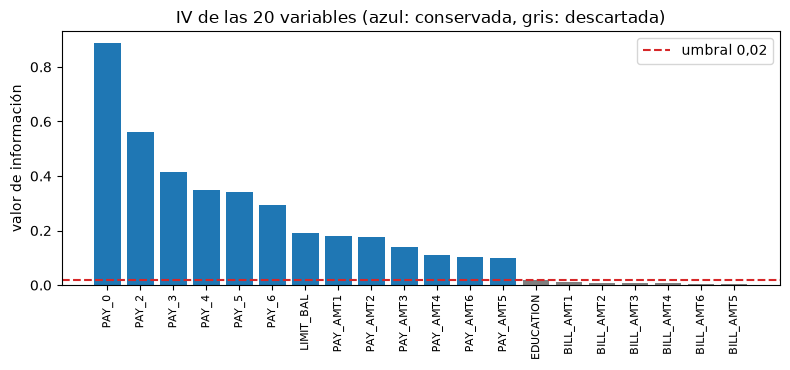

In [7]:
# Dibujar el valor de información de cada variable frente al umbral de filtro de 0,02
fig, ax = plt.subplots(figsize=(8, 3.8))
names = [n for n, _ in ranked]
values = [v for _, v in ranked]
colors = ["tab:blue" if n in card["features"] else "tab:gray" for n in names]
ax.bar(range(len(names)), values, color=colors)
ax.axhline(0.02, color="tab:red", linestyle="--", label="umbral 0,02")
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_ylabel("valor de información")
ax.set_title("IV de las 20 variables (azul: conservada, gris: descartada)")
ax.legend()
fig.tight_layout()
plt.show()


### Paso 4: un modelo logístico sobre el WoE

Cada variable conservada entra al modelo por su WoE, de modo que el modelo es lineal en la evidencia de los tramos. Con $k$ variables, $\mathrm{WoE}_j(x_j)$ el WoE del tramo de la variable $j$ en que cae la tarjeta y $\eta$ el logaritmo de las probabilidades relativas **del evento** en la convención de signo del dossier del pipeline:

$$\eta(x) = \beta_0 + \sum_{j=1}^{k} \beta_j\,\mathrm{WoE}_j(x_j), \qquad \mathrm{PD}(x) = \frac{1}{1 + e^{-\eta(x)}}$$

Como un WoE más alto significa un riesgo menor, todos los coeficientes de una tarjeta de puntaje sana son **negativos**: una tarjeta en un mejor tramo debe tener un $\eta$ menor. Un coeficiente positivo es una señal de que dos variables llevan la misma información y se la disputan (el pipeline descarta la variable de signo erróneo con mayor valor p y reajusta). La siguiente celda imprime el intercepto y los 13 coeficientes y verifica los signos.

In [8]:
# Imprimir el intercepto y los coeficientes y verificar que todos son negativos
print("intercepto beta_0:", round(card["intercept"], 4))
for name in card["features"]:
    print(f"{name:10s} beta {card['coefficients'][name]:8.4f}")
print("todos los coeficientes negativos:", si_no(all(b < 0 for b in card["coefficients"].values())))


intercepto beta_0: -1.2517
LIMIT_BAL  beta  -0.3135
PAY_0      beta  -0.7435
PAY_2      beta  -0.0786
PAY_3      beta  -0.1533
PAY_4      beta  -0.0958
PAY_5      beta  -0.1925
PAY_6      beta  -0.2195
PAY_AMT1   beta  -0.1378
PAY_AMT2   beta  -0.2768
PAY_AMT3   beta  -0.2639
PAY_AMT4   beta  -0.1114
PAY_AMT5   beta  -0.0840
PAY_AMT6   beta  -0.1704
todos los coeficientes negativos: sí


### Paso 5: la escala de los puntos

Un modelo que entrega un logaritmo de probabilidades relativas es difícil de usar en un escritorio. Una tarjeta de puntaje lo convierte en un puntaje lineal en el logaritmo de las probabilidades relativas de ser **bueno**, y fija la escala con tres números (Siddiqi, 2017; la fórmula tal como la implementa `skorecard` de ING, de código abierto):

$$\mathrm{Puntaje} = \mathrm{Offset} + \mathrm{Factor}\cdot\ln(\mathrm{odds}_{bueno}), \qquad \mathrm{Factor} = \frac{\mathrm{PDO}}{\ln 2}, \qquad \mathrm{Offset} = \mathrm{Puntaje}_{ref} - \mathrm{Factor}\cdot\ln(\mathrm{odds}_{ref})$$

Los **puntos para duplicar las probabilidades relativas** (PDO) son los puntos que duplican las probabilidades relativas de ser bueno: con un PDO de 20, una tarjeta con 20 puntos más tiene el doble de probabilidades relativas de ser buena. Esta tarjeta de puntaje fija PDO = 20, un puntaje de referencia de 600 con probabilidades relativas de referencia de 50 a 1. La siguiente celda recalcula el Factor y el Offset y los compara con la escala versionada.

In [9]:
# Recalcular el Factor y el Offset desde los tres números de la escala
pdo, odds_ref, score_ref = 20.0, 50.0, 600.0
factor = pdo / np.log(2.0)
offset = score_ref - factor * np.log(odds_ref)
print("PDO:", pdo, "| odds_ref:", odds_ref, "| score_ref:", score_ref)
print("Factor:", round(float(factor), 6), "| versionado:", round(card["scaling"]["factor"], 6))
print("Offset:", round(float(offset), 6), "| versionado:", round(card["scaling"]["offset"], 6))


PDO: 20.0 | odds_ref: 50.0 | score_ref: 600.0
Factor: 28.853901 | versionado: 28.853901
Offset: 487.122876 | versionado: 487.122876


### Paso 6: los puntos de un tramo

El puntaje total debe ser igual a $\mathrm{Offset} - \mathrm{Factor}\cdot\eta$ (el signo menos es la convención de WoE del pipeline: un $\eta$ más alto es una tarjeta más riesgosa, así que debe perder puntos). Para obtenerlo como una **suma de puntos por tramo**, el offset y el intercepto se reparten por igual entre las $k$ variables (la fórmula de `skorecard`):

$$\mathrm{Puntos}_{j,b} = \frac{\mathrm{Offset}}{k} - \left(\beta_j\,\mathrm{WoE}_{j,b} + \frac{\beta_0}{k}\right)\mathrm{Factor}$$

Sumar sobre las $k$ variables da exactamente $\mathrm{Offset} - \mathrm{Factor}\,\eta$. Luego los puntos se **redondean a enteros**, porque una tarjeta de puntaje es una tabla impresa. La siguiente celda recalcula los puntos sin redondear de cada fila de la tabla versionada desde su WoE y los coeficientes, los compara, los redondea e imprime dos variables como las vería quien usa la tarjeta.

In [10]:
# Recalcular los puntos de cada fila de la tabla desde su WoE y los coeficientes, y redondearlos
k = len(card["features"])
beta_0 = card["intercept"]
raw_gap, round_gap = 0.0, 0
for row in table:
    beta = card["coefficients"][row["feature"]]
    points_raw = offset / k - (beta * row["woe"] + beta_0 / k) * factor
    raw_gap = max(raw_gap, abs(points_raw - row["points_raw"]))
    round_gap = max(round_gap, abs(int(round(points_raw)) - row["points"]))
print("filas verificadas:", len(table), "| variables k:", k)
print("mayor diferencia de los puntos sin redondear:", f"{raw_gap:.2e}")
print("mayor diferencia de los puntos redondeados (en puntos):", round_gap)
for feature in ("PAY_0", "LIMIT_BAL"):
    print()
    print(feature)
    for row in table:
        if row["feature"] == feature and row["count"] > 0:
            print(f"  {row['bin']:>26s}  WoE {row['woe']:7.3f}  puntos {row['points_raw']:7.2f} -> {row['points']:3d}")


filas verificadas: 95 | variables k: 13
mayor diferencia de los puntos sin redondear: 0.00e+00
mayor diferencia de los puntos redondeados (en puntos): 0

PAY_0
               (-inf, -1.50)  WoE   0.637  puntos   53.91 ->  54
               [-1.50, 0.50)  WoE   0.581  puntos   52.72 ->  53
                [0.50, 1.50)  WoE  -0.585  puntos   27.70 ->  28
                 [1.50, inf)  WoE  -2.090  puntos   -4.60 ->  -5

LIMIT_BAL
            (-inf, 45000.00)  WoE  -0.717  puntos   33.77 ->  34
        [45000.00, 75000.00)  WoE  -0.241  puntos   38.07 ->  38
       [75000.00, 105000.00)  WoE  -0.119  puntos   39.18 ->  39
      [105000.00, 145000.00)  WoE  -0.078  puntos   39.54 ->  40
      [145000.00, 165000.00)  WoE   0.226  puntos   42.29 ->  42
      [165000.00, 245000.00)  WoE   0.301  puntos   42.97 ->  43
      [245000.00, 375000.00)  WoE   0.524  puntos   44.99 ->  45
            [375000.00, inf)  WoE   0.771  puntos   47.22 ->  47


### Paso 7: el puntaje de una tarjeta es una suma

Para puntuar una tarjeta se busca su tramo en cada una de las 13 variables y se suman los puntos. El artefacto de la muestra reservada guarda 50 tarjetas con sus 13 columnas de puntos y el puntaje que les dio el pipeline, así que la afirmación se puede verificar: el puntaje debe ser la suma de los puntos, y nada más. La siguiente celda suma los puntos de las 50 tarjetas, compara con el puntaje versionado e imprime las tres primeras tarjetas con sus puntos por variable.

In [11]:
# Sumar las 13 columnas de puntos de las 50 tarjetas de la muestra y comparar la suma con el puntaje versionado
sample = holdout["outputs"]["sample"]
y = np.array(sample["targets"])
points = np.array(sample["scorecard_points"])
score = np.array(sample["scorecard_score"])
print("tarjetas:", points.shape[0], "| columnas de puntos:", points.shape[1])
print("el puntaje es la suma de los puntos en todas las tarjetas:", si_no((points.sum(axis=1) == score).all()))
print(f"{'':8s}" + "".join(f"{name.replace('PAY_AMT', 'AMT').replace('LIMIT_BAL', 'LIMIT'):>8s}" for name in card["features"]) + f"{'puntaje':>8s}")
for i in range(3):
    print(f"{sample['ids'][i]:8s}" + "".join(f"{int(p):8d}" for p in points[i]) + f"{int(score[i]):8d}")


tarjetas: 50 | columnas de puntos: 13
el puntaje es la suma de los puntos en todas las tarjetas: sí
           LIMIT   PAY_0   PAY_2   PAY_3   PAY_4   PAY_5   PAY_6    AMT1    AMT2    AMT3    AMT4    AMT5    AMT6 puntaje
TW00002       40      53      37      42      41      41      32      38      39      40      40      39      40     522
TW00004       38      53      41      42      41      41      42      40      40      40      40      40      40     538
TW00012       45      53      41      42      41      42      32      44      46      44      43      39      41     553


### Paso 8: del puntaje de vuelta a una PD

El puntaje es un logaritmo de probabilidades relativas reescalado, así que se puede volver a convertir en una probabilidad sin el modelo. De $\mathrm{Puntaje} = \mathrm{Offset} - \mathrm{Factor}\,\eta$ se obtiene $\eta = (\mathrm{Offset} - \mathrm{Puntaje}) / \mathrm{Factor}$, y la PD es la función logística de $\eta$. Hay un detalle: la PD versionada viene del modelo **sin redondear**, mientras que el puntaje suma puntos **redondeados**, así que las dos PD difieren por el redondeo. La siguiente celda calcula la PD desde el puntaje, la compara con la PD versionada de las 50 tarjetas y verifica la propiedad del PDO: 20 puntos más deben reducir a la mitad las probabilidades relativas de incumplimiento.

In [12]:
# Volver a convertir el puntaje en PD, compararla con la PD versionada y verificar la propiedad de puntos para duplicar las probabilidades relativas
pd_model = np.array(sample["scorecard_pd"])
eta = (offset - score) / factor
pd_points = 1.0 / (1.0 + np.exp(-eta))
gap = np.abs(pd_points - pd_model)
print("mayor brecha de PD, puntos contra modelo:", round(float(gap.max()), 4), "| media:", round(float(gap.mean()), 4))
print("PD media del modelo:", round(float(pd_model.mean()), 4), "| desde los puntos:", round(float(pd_points.mean()), 4))
# Las probabilidades relativas de incumplimiento en un puntaje y en el puntaje 20 puntos más alto
def default_odds(s):
    p = 1.0 / (1.0 + np.exp(-(offset - s) / factor))
    return p / (1.0 - p)

print("razón de las probabilidades relativas de incumplimiento en 560 y en 580:", round(float(default_odds(560.0) / default_odds(580.0)), 6))


mayor brecha de PD, puntos contra modelo: 0.0084 | media: 0.003
PD media del modelo: 0.2534 | desde los puntos: 0.2513
razón de las probabilidades relativas de incumplimiento en 560 y en 580: 2.0


### Paso 9: ordenamiento y grados sobre las tarjetas reservadas

Una tarjeta de puntaje se juzga primero por cómo ordena. La función `disc_auc` del motor recibe un valor de riesgo por tarjeta (más alto es más riesgoso) y los resultados, y devuelve el AUC con su error estándar e intervalo (Hanley y McNeil, 1982; ECB 2019, Anexo 1, sección 3.1). La siguiente celda la llama sobre las 50 tarjetas dos veces, con la PD del modelo y con la PD reconstruida desde los puntos enteros, para ver si el redondeo cambia el ordenamiento, y luego lee el AUC versionado de la tarjeta de puntaje sobre las 9.000 tarjetas reservadas. Después, los 12 grados de la escala maestra (cotas superiores 1% por 1,5 elevado a k) agrupan las 9.000 tarjetas por PD, y para cada grado la tabla versionada da las tarjetas, los incumplimientos, la PD media y la tasa de incumplimiento observada.

In [13]:
# El AUC del motor sobre las 50 tarjetas con la PD del modelo y con la PD reconstruida desde los puntos, y el AUC versionado sobre 9.000 tarjetas
from riskvalidation.validation import disc_auc

policy = rv.default_policy()
auc_model = disc_auc(pd_model, y, policy=policy, model_id="P1-scorecard")
auc_points = disc_auc(pd_points, y, policy=policy, model_id="P1-scorecard")
committed = next(t for t in holdout["tests"] if t["test_id"] == "disc.auc" and t["model_id"] == "P1-scorecard" and t["segment"] == "portfolio")
print("AUC 50 tarjetas, PD del modelo:", round(auc_model.metric, 4), "| intervalo del 95%:", round(auc_model.extras["ci95_low"], 3), "a", round(auc_model.extras["ci95_high"], 3))
print("AUC 50 tarjetas, PD desde los puntos:", round(auc_points.metric, 4))
print("AUC 9000 tarjetas, versionado:", round(committed["metric"], 4), "| intervalo del 95%:", round(committed["extras"]["ci95_low"], 4), "a", round(committed["extras"]["ci95_high"], 4))
print("versionado por riskvalidation", holdout["provenance"]["riskvalidation_version"])


AUC 50 tarjetas, PD del modelo: 0.7752 | intervalo del 95%: 0.646 a 0.904
AUC 50 tarjetas, PD desde los puntos: 0.7781
AUC 9000 tarjetas, versionado: 0.7587 | intervalo del 95%: 0.7461 a 0.7714
versionado por riskvalidation 1.0.1


Los 12 grados de la escala maestra agrupan las 9.000 tarjetas por PD. La siguiente celda imprime la tabla de grados versionada sin los grados vacíos: las tarjetas, los incumplimientos, la PD media y la tasa de incumplimiento observada de cada grado.

In [14]:
# Imprimir los grados de la tarjeta de puntaje sobre las 9.000 tarjetas reservadas, sin los vacíos
grades = [g for g in holdout["outputs"]["rungs"]["P1-scorecard"]["grades"] if g["n"] > 0]
print(f"{'grado':6s} {'PD superior':>9s} {'tarjetas':>7s} {'incumpl.':>9s} {'PD media':>8s} {'tasa':>7s}")
for g in grades:
    print(f"{g['grade']:6s} {g['hi']:9.4f} {g['n']:7d} {g['d']:9d} {g['pd']:8.4f} {g['dr']:7.4f}")
print("tarjetas en los grados:", sum(g["n"] for g in grades), "| incumplimientos:", sum(g["d"] for g in grades))


grado  PD superior tarjetas  incumpl. PD media    tasa
G05       0.0506      68         4   0.0468  0.0588
G06       0.0759     698        54   0.0653  0.0774
G07       0.1139    1862       155   0.0950  0.0832
G08       0.1709    3101       466   0.1399  0.1503
G09       0.2563    1224       251   0.1990  0.2051
G10       0.3844     719       251   0.3241  0.3491
G11       0.5767     510       251   0.4762  0.4922
G12       1.0000     818       559   0.7243  0.6834
tarjetas en los grados: 9000 | incumplimientos: 1991


La última figura dibuja la PD media y la tasa de incumplimiento observada de cada grado lado a lado: donde las barras difieren, la PD de la tarjeta de puntaje se equivoca en ese grado.

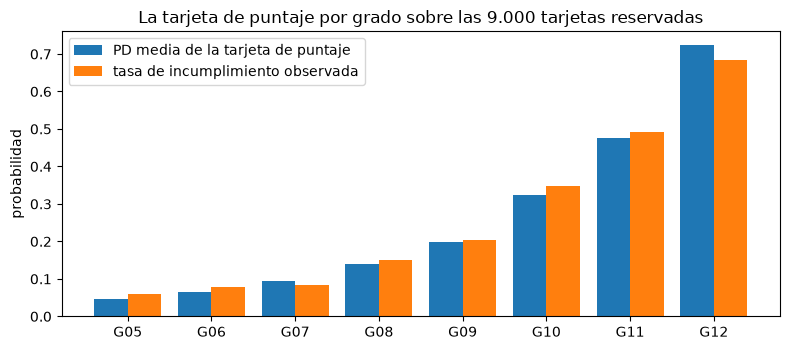

In [15]:
# Dibujar la PD media y la tasa de incumplimiento observada de cada grado
fig, ax = plt.subplots(figsize=(8, 3.6))
positions = np.arange(len(grades))
ax.bar(positions - 0.2, [g["pd"] for g in grades], width=0.4, label="PD media de la tarjeta de puntaje")
ax.bar(positions + 0.2, [g["dr"] for g in grades], width=0.4, label="tasa de incumplimiento observada")
ax.set_xticks(positions)
ax.set_xticklabels([g["grade"] for g in grades])
ax.set_ylabel("probabilidad")
ax.set_title("La tarjeta de puntaje por grado sobre las 9.000 tarjetas reservadas")
ax.legend()
fig.tight_layout()
plt.show()


## Resultados

- **El WoE y el IV son conteos, nada más.** Recalculados desde los conteos de los tramos del tramo de entrenamiento, el WoE de cada tramo de `PAY_0` y su IV (0,886) coinciden con los valores versionados salvo error de redondeo. La variable lleva por lejos la mayor evidencia: las tarjetas con dos o más meses de atraso incumplen cerca del 70%, frente al 13% a 14% de las que pagaron a tiempo o rotaron.
- **El filtro se ve.** De 20 variables, 13 alcanzan el umbral de 0,02. `EDUCATION` queda justo debajo (0,0189) y los seis montos de cuenta llevan casi nada de evidencia una vez que el estado de pago está en el modelo. Los 13 coeficientes son negativos, como exige una tarjeta de puntaje sana.
- **La tabla de puntos es el modelo.** Cada una de las 95 filas de la tabla se obtiene de su WoE, los coeficientes y los tres números de la escala, y los puntos redondeados difieren de los no redondeados en a lo más medio punto por variable. El puntaje de cada una de las 50 tarjetas de la muestra es exactamente la suma de sus 13 puntos.
- **El redondeo cuesta un poco.** La PD reconstruida desde el puntaje entero difiere de la PD versionada hasta cerca de 0,008 en las 50 tarjetas, porque los puntos enteros pierden los decimales que el modelo conserva. El ordenamiento casi no cambia: el AUC de ambas difiere en cerca de 0,003 en estas tarjetas (0,775 frente a 0,778). La propiedad del PDO se cumple exactamente: 20 puntos reducen a la mitad las probabilidades relativas (la razón es 2).
- **Ordenamiento y grados.** El AUC sobre las 9.000 tarjetas reservadas es 0,759, con un intervalo angosto. La tasa de incumplimiento sube de grado en grado. Solo ocho de los doce grados tienen tarjetas, y la tasa observada queda sobre la PD media en los grados G05 a G11 y bajo ella en G12: las PD son algo bajas para la mayoría de las tarjetas. Esa es una pregunta para las pruebas de calibración, y las filas versionadas ya la señalan (cuaderno 03 de este tema).

Lo que este cuaderno no muestra: cómo se ajustan los tramos y los coeficientes (cuaderno 02), cómo se compara la tarjeta de puntaje con otros modelos (cuadernos 03 y 06), ni si el ajuste se sostiene fuera del tiempo (cuadernos 04 y 07). La muestra de 50 tarjetas es demasiado pequeña para decir algo sobre la calidad de la tarjeta de puntaje; el intervalo del AUC con 50 tarjetas es ancho, como mostró el cuaderno 02 del tema 01.

## Resumen

- El WoE compara la proporción de no eventos y la de eventos en un tramo; el IV suma la diferencia sobre los tramos; ambos se calculan desde conteos y se recalculan aquí salvo redondeo.
- Un modelo logístico sobre el WoE tiene coeficientes negativos cuando es sano; el intercepto y los coeficientes se reparten por variable en una tabla de puntos con $\mathrm{Puntos}_{j,b} = \mathrm{Offset}/k - (\beta_j \mathrm{WoE}_{j,b} + \beta_0/k)\,\mathrm{Factor}$.
- La escala la fijan el PDO, un puntaje de referencia y unas probabilidades relativas de referencia; 20 puntos duplican las probabilidades relativas de ser bueno.
- El puntaje es la suma de los puntos enteros, la PD se puede reconstruir desde él sin el modelo, y el redondeo cuesta una brecha de PD pequeña y medible, no un cambio de ordenamiento.

**Qué probar después.** Lee `docs/guides/03_read-a-validation-report.md` para ver las luces que llevan las filas versionadas de esta tarjeta de puntaje, y continúa con el cuaderno 02, que muestra cómo se ajustan los tramos y los coeficientes y por qué el ajuste debe ver solo el tramo de entrenamiento.

## Referencias

- Navas-Palencia, G. (2020), Optimal binning: mathematical programming formulation, sección 2.1 (WoE e IV). https://arxiv.org/abs/2001.08025
- Siddiqi, N. (2017), Intelligent Credit Scoring: Building and Implementing Better Credit Risk Scorecards, 2.ª ed., Wiley. https://doi.org/10.1002/9781119282396 (la fórmula de la escala se verifica en la implementación abierta, `skorecard` de ING, https://github.com/ing-bank/skorecard/blob/main/skorecard/rescale/rescale.py; la página del libro de la fórmula y del umbral 0,02 está SIN VERIFICAR en la investigación.)
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients